> **Before you run this notebook.** It reads two files.
>
> * **BRFSS 2015 (Part A):** `diabetes_binary_health_indicators_BRFSS2015.csv` from the Kaggle dataset
>   *Diabetes Health Indicators Dataset* (`kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset`).
>   It is **not in git**; put it in `data/raw/` (on Colab: upload it to the session folder).
> * **Synthetic demo readings (Part B):** `data/synthetic/demo_glucose_sequences.csv` **is in git**. It was
>   written by `uv run python -m scripts.export_hmm_sequences` from the app's demo generator (no database).
>   On Colab, upload it to the session folder as well.
> * **Local packages:** `uv sync --group notebook` (matplotlib, pillow, scipy). Colab already has them.

# PBL 2 — Unsupervised learning and Hidden Markov Models (Team 6)

**Course:** Machine Learning mini project · **Units 3 and 4:** K-means, PCA, Hidden Markov Model,
sum-product algorithm

This notebook has two parts with **different status**:

| Part | Data | What it is |
|---|---|---|
| **A** — PCA and K-means | real CDC BRFSS 2015 survey (real-prevalence file, de-duplicated as in notebook 01) | an **exploratory analysis** of the survey population |
| **B** — HMM and sum-product | **synthetic** demo glucose readings from the app's seed generator | a **method demonstration** only |

| Section | Syllabus topic |
|---|---|
| A1 | **PCA** from scratch, checked against scikit-learn; does PCA help the classifier? |
| A2 | **K-means** (Lloyd + k-means++) from scratch, checked against scikit-learn; choosing *k*; cluster profiles |
| B0–B2 | **Hidden Markov Model**: forward, backward, forward-backward, Viterbi, Baum-Welch, brute-force check |
| B3 | **Sum-product** message passing on the HMM's chain factor graph (and max-product = Viterbi) |
| C | Conclusions, limitations, and how each method relates to the advisor |

> **What this notebook does *not* claim.**
> * Part B detects nothing in real patients. The readings are synthetic, and the app **never** uses this
>   HMM to raise an alert or to change a glucose limit. Alerts come only from the threshold engine.
> * The K-means clusters are groups of similar survey answers, **not clinical types** of diabetes.
> * PCA is studied as a tool; we test whether it improves the risk model and report the answer honestly.
> * The HMM's hidden states are a summary of synthetic band states; they are **not** a measure of real
>   glycaemic control.

## Setup

Run from the project's `notebooks/` folder (data is read from `../data/raw` and `../data/synthetic`).
On **Google Colab**, upload the two CSVs first; the paths are detected automatically.

In [1]:
# Standard library
import itertools
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Literal, NamedTuple

# Third-party
import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import pandas as pd
from IPython.display import display
from matplotlib.colors import ListedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    adjusted_rand_score,
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

FloatArray = npt.NDArray[np.float64]
IntArray = npt.NDArray[np.int64]
RANDOM_STATE = 42  # one seed for every split, sample and random restart -> reproducible results
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 4)
NOTEBOOK_START = time.perf_counter()  # total runtime is printed at the end

BRFSS_FILE = "diabetes_binary_health_indicators_BRFSS2015.csv"
SEQUENCE_FILE = "demo_glucose_sequences.csv"
# Repo layout: notebooks/ sits next to data/. On Colab, CSVs are uploaded to the cwd.
DATA_DIR = next(
    (p for p in (Path("../data/raw"), Path("data/raw"), Path(".")) if (p / BRFSS_FILE).exists()),
    Path("."),
)
SYNTHETIC_DIR = next(
    (p for p in (Path("../data/synthetic"), Path("data/synthetic"), Path("."))
     if (p / SEQUENCE_FILE).exists()),
    Path("."),
)
print("BRFSS data from:    ", DATA_DIR.resolve())
print("Synthetic data from:", SYNTHETIC_DIR.resolve())

BRFSS data from:     <project>/data/raw
Synthetic data from: <project>/data/synthetic


# Part A — PCA and K-means on the BRFSS 2015 survey

## A0. Load the real-prevalence file

Same cleaning as notebook 01: check for nulls and codebook ranges, then drop exact duplicate rows
(identical survey answers would otherwise count several times). The label `Diabetes_binary` is
**not** an input to PCA or K-means; it is only used afterwards to describe what was found.

In [2]:
raw = pd.read_csv(DATA_DIR / BRFSS_FILE)
LABEL = "Diabetes_binary"
FEATURES = [c for c in raw.columns if c != LABEL]
CONTINUOUS = ["BMI", "MentHlth", "PhysHlth"]
ORDINAL = ["GenHlth", "Age", "Education", "Income"]
BINARY_COLS = [c for c in FEATURES if c not in CONTINUOUS + ORDINAL]

# Valid ranges from the BRFSS codebook (as in notebook 01); anything outside means corrupted data.
RANGES = {**{c: (0, 1) for c in BINARY_COLS}, "BMI": (12, 98), "MentHlth": (0, 30),
          "PhysHlth": (0, 30), "GenHlth": (1, 5), "Age": (1, 13), "Education": (1, 6),
          "Income": (1, 8)}
assert raw.isna().sum().sum() == 0, "unexpected nulls"
bad = {c: int(((raw[c] < lo) | (raw[c] > hi)).sum()) for c, (lo, hi) in RANGES.items()}
assert sum(bad.values()) == 0, f"out-of-range values {bad}"

data = raw.drop_duplicates().reset_index(drop=True).astype(float)
x_raw: FloatArray = data[FEATURES].to_numpy()
y_all = data[LABEL].to_numpy().astype(int)
print(f"{len(raw):,} rows -> {len(data):,} after dropping {len(raw) - len(data):,} duplicates; "
      f"{len(FEATURES)} features ({len(BINARY_COLS)} binary, {len(ORDINAL)} ordinal, "
      f"{len(CONTINUOUS)} count/continuous); diabetes prevalence {y_all.mean():.3f}")

253,680 rows -> 229,474 after dropping 24,206 duplicates; 21 features (14 binary, 4 ordinal, 3 count/continuous); diabetes prevalence 0.153


## A1. Principal Component Analysis (PCA)

PCA finds orthogonal directions $w_1, w_2, \dots$ of maximum variance. With the centred data matrix
$X_c$ ($n \times d$), the sample covariance is $\Sigma = \tfrac{1}{n-1} X_c^\top X_c$; its eigenvectors
are the principal axes and its eigenvalues $\lambda_j$ are the variance along each axis. Projecting,
$Z = X_c W_k$, keeps the $k$ axes with the largest $\lambda_j$. (Equivalently, the right singular
vectors of $X_c$ from an SVD; scikit-learn uses the SVD.)

**Standardise first.** BMI ranges 12–98 while the binary answers are 0/1; without scaling, PCA would
mostly describe BMI, MentHlth and PhysHlth because they have the largest raw variance.

> **Caveat:** 14 of the 21 features are binary and 4 are ordinal, so "variance along a direction" is
> only an approximation here. Multiple Correspondence Analysis (MCA) or Factor Analysis of Mixed Data
> (FAMD) are the proper tools for categorical / mixed data; they are not used in this notebook.

In [3]:
def standardise(x: FloatArray) -> tuple[FloatArray, FloatArray, FloatArray]:
    """Scale every column to mean 0 and standard deviation 1.

    Args:
        x: Data, shape (n, d).

    Returns:
        The standardised data, the column means and the column standard deviations (ddof=0,
        the same convention as scikit-learn's ``StandardScaler``).
    """
    mean = x.mean(axis=0)
    std = x.std(axis=0)
    return (x - mean) / std, mean, std


def pca_from_scratch(x: FloatArray) -> tuple[FloatArray, FloatArray, FloatArray]:
    """Principal components by eigen-decomposition of the sample covariance matrix.

    Args:
        x: Data, shape (n, d).

    Returns:
        ``components`` of shape (d, d), one unit-length principal axis per **row**, sorted by
        decreasing variance; the variance along each axis (eigenvalues, shape (d,)); and the
        column means used for centring.
    """
    mean = x.mean(axis=0)
    centred = x - mean
    cov = centred.T @ centred / (len(x) - 1)  # 1/(n-1): same convention as scikit-learn
    eigvals, eigvecs = np.linalg.eigh(cov)  # eigh: cov is symmetric -> real, orthonormal result
    order = np.argsort(eigvals)[::-1]
    return eigvecs[:, order].T, eigvals[order], mean


def pca_project(x: FloatArray, components: FloatArray, mean: FloatArray, k: int) -> FloatArray:
    """Project data onto the first ``k`` principal axes.

    Args:
        x: Data, shape (n, d).
        components: Principal axes as rows, from :func:`pca_from_scratch`.
        mean: Column means used for centring.
        k: Number of components to keep.

    Returns:
        PCA scores, shape (n, k).
    """
    return (x - mean) @ components[:k].T


z_all, _, _ = standardise(x_raw)
components, eigvals, pca_mean = pca_from_scratch(z_all)
# An eigenvector's sign is arbitrary. Fix it so PC1 and PC2 point towards *worse* self-rated
# general health (GenHlth: 1 = excellent ... 5 = poor), which makes the plots easier to read.
genhlth = FEATURES.index("GenHlth")
components *= np.where(components[:, genhlth] < 0, -1.0, 1.0)[:, None]
scores_all = pca_project(z_all, components, pca_mean, len(FEATURES))
explained_ratio = eigvals / eigvals.sum()
print(f"Total variance {eigvals.sum():.3f} (= number of standardised features, up to n/(n-1))")

Total variance 21.000 (= number of standardised features, up to n/(n-1))


**Check against scikit-learn.** The eigenvalues must equal `explained_variance_`, and each component
must equal scikit-learn's *up to sign* (an eigenvector $w$ and $-w$ describe the same axis).

In [4]:
sk_pca = PCA(random_state=RANDOM_STATE).fit(z_all)
signs = np.sign(np.sum(components * sk_pca.components_, axis=1))  # +1 or -1 per component

assert np.allclose(eigvals, sk_pca.explained_variance_, rtol=1e-8)
assert np.allclose(explained_ratio, sk_pca.explained_variance_ratio_, rtol=1e-8)
assert np.allclose(components * signs[:, None], sk_pca.components_, atol=1e-6)
assert np.allclose(scores_all * signs, sk_pca.transform(z_all), atol=1e-6)
print("PCA from scratch == scikit-learn PCA (explained variance equal, components equal up to sign)")
print("Sign flips needed per component:", "".join("+" if s > 0 else "-" for s in signs))

PCA from scratch == scikit-learn PCA (explained variance equal, components equal up to sign)
Sign flips needed per component: +-+++++-+-+------+---


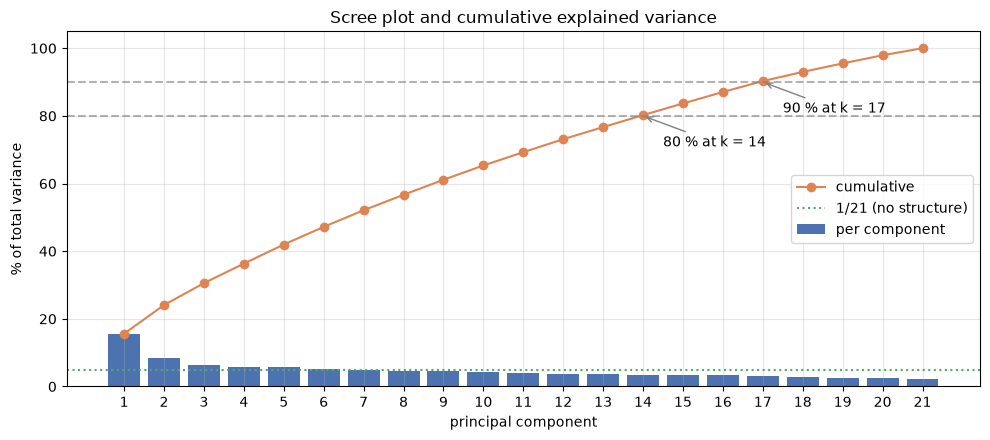

80 % of the variance needs 14 components, 90 % needs 17 (of 21).


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
explained %,15.6184,8.4622,6.4805,5.7763,5.6366,5.2183,4.9150,4.5670
cumulative %,15.6184,24.0806,30.5611,36.3374,41.9739,47.1922,52.1072,56.6743


In [5]:
cumulative = np.cumsum(explained_ratio)
k80 = int(np.searchsorted(cumulative, 0.80) + 1)
k90 = int(np.searchsorted(cumulative, 0.90) + 1)

fig, ax = plt.subplots(figsize=(10, 4.5))
pcs = np.arange(1, len(FEATURES) + 1)
ax.bar(pcs, explained_ratio * 100, color="#4C72B0", label="per component")
ax.plot(pcs, cumulative * 100, marker="o", color="#DD8452", label="cumulative")
for level, k in ((80, k80), (90, k90)):
    ax.axhline(level, color="grey", linestyle="--", alpha=0.6)
    ax.annotate(f"{level} % at k = {k}", (k, level), xytext=(k + 0.5, level - 9),
                arrowprops={"arrowstyle": "->", "color": "grey"})
ax.axhline(100 / len(FEATURES), color="#55A868", linestyle=":", label="1/21 (no structure)")
ax.set(title="Scree plot and cumulative explained variance", xlabel="principal component",
       ylabel="% of total variance", xticks=pcs)
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

print(f"80 % of the variance needs {k80} components, 90 % needs {k90} (of {len(FEATURES)}).")
pd.DataFrame({"explained %": explained_ratio[:8] * 100, "cumulative %": cumulative[:8] * 100},
             index=[f"PC{i}" for i in range(1, 9)]).T

**Observation:** the variance is spread thinly. PC1 explains 15.6 % and PC2 8.5 %; after that each
component adds only about 4–6.5 %, close to the 1/21 ≈ 4.8 % that a component would get if the
features were unrelated. 80 % of the variance needs **14** components and 90 % needs **17** of the 21.
So there is one moderately strong common direction and little else: the survey answers do not
compress well into a few dimensions.

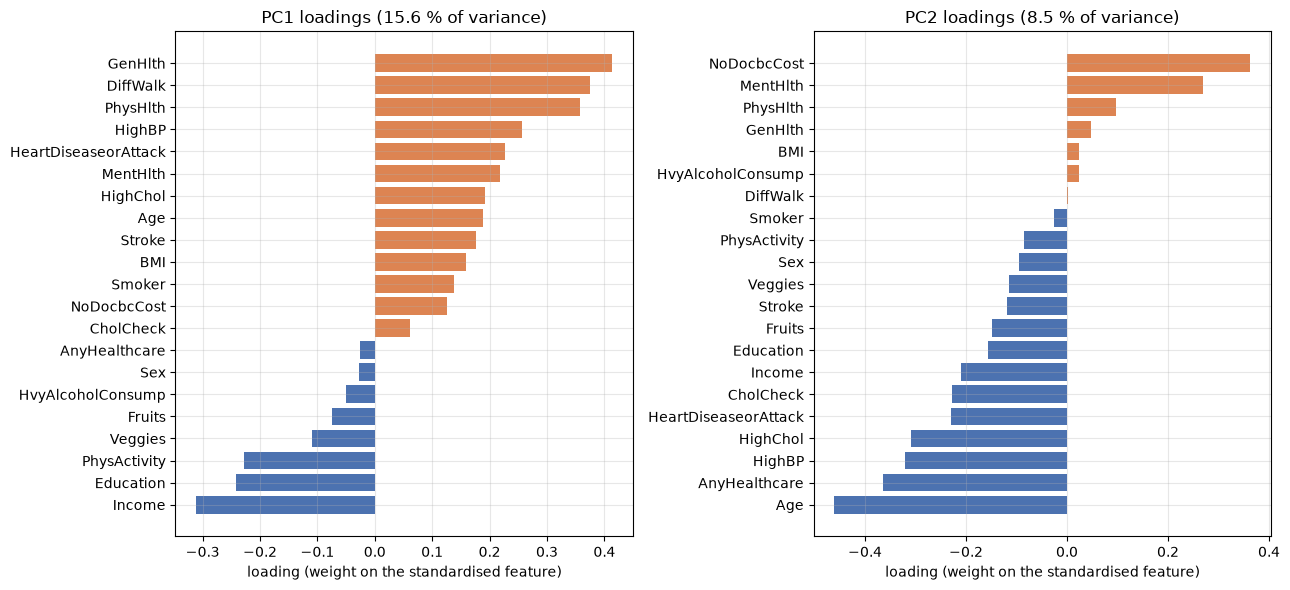

,PC1,PC2
GenHlth,0.4138,0.0467
DiffWalk,0.3752,0.0026
PhysHlth,0.3570,0.0962
HighBP,0.2568,-0.3217
HeartDiseaseorAttack,0.2266,-0.2298
MentHlth,0.2190,0.2696
HighChol,0.1923,-0.3082
Age,0.1884,-0.4606
Stroke,0.1757,-0.1193
BMI,0.1592,0.0240


In [6]:
loadings = pd.DataFrame(components[:2].T, index=FEATURES, columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=False)
for ax, pc in zip(axes, ["PC1", "PC2"]):
    ordered = loadings[pc].sort_values()
    ax.barh(ordered.index, ordered.values,
            color=["#DD8452" if v > 0 else "#4C72B0" for v in ordered.values])
    ax.set(title=f"{pc} loadings ({explained_ratio[int(pc[-1]) - 1] * 100:.1f} % of variance)",
           xlabel="loading (weight on the standardised feature)")
plt.tight_layout()
plt.show()
loadings.sort_values("PC1", ascending=False)

**Interpretation.**
* **PC1 (15.6 %) — "overall health burden".** Large positive loadings on poor self-rated general
  health (GenHlth), difficulty walking (DiffWalk), days of poor physical health (PhysHlth), high blood
  pressure, heart disease, poor mental-health days and high cholesterol; negative loadings on income,
  education and physical activity. A high PC1 score means worse health and lower socioeconomic status.
* **PC2 (8.5 %) — "younger, with poorer access to care" versus "older, cardiometabolic".** Positive
  loadings on not seeing a doctor because of cost (NoDocbcCost) and on mental-health days; negative
  loadings on age, having health-care coverage (AnyHealthcare), high blood pressure, high cholesterol,
  heart disease and a cholesterol check. A low PC2 score describes an older person with known
  cardiovascular risk factors who is in regular contact with health care.

These are descriptions of how the answers co-vary, not causal factors.

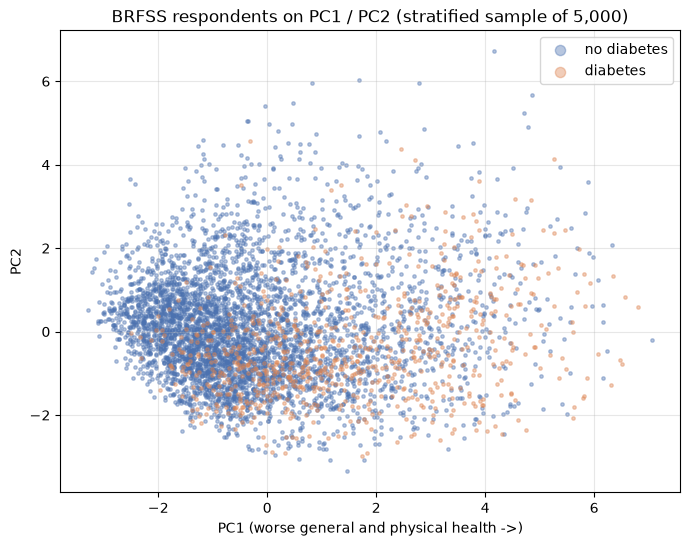

,mean PC1,mean PC2
no diabetes,-0.2534,0.0799
diabetes,1.4035,-0.4423


In [7]:
# Stratified sample: 5,000 points keep the plot readable and the diabetes share of the full data.
sample_idx, _ = train_test_split(np.arange(len(data)), train_size=5000, stratify=y_all,
                                 random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 6))
for label, color, name in [(0, "#4C72B0", "no diabetes"), (1, "#DD8452", "diabetes")]:
    pts = sample_idx[y_all[sample_idx] == label]
    ax.scatter(scores_all[pts, 0], scores_all[pts, 1], s=6, alpha=0.4, color=color, label=name)
ax.set(title="BRFSS respondents on PC1 / PC2 (stratified sample of 5,000)",
       xlabel="PC1 (worse general and physical health ->)", ylabel="PC2")
ax.legend(markerscale=3)
plt.show()

pd.DataFrame({"mean PC1": [scores_all[y_all == c, 0].mean() for c in (0, 1)],
              "mean PC2": [scores_all[y_all == c, 1].mean() for c in (0, 1)]},
             index=["no diabetes", "diabetes"])

**Observation:** people with diabetes sit much further along PC1 (mean score 1.40 against −0.25) and
slightly lower on PC2 (older, more blood-pressure and cholesterol problems). But the two groups overlap
heavily in the plane: two components describe the population; they do not separate it.

### Does PCA help the classifier?

A common claim is that PCA "improves" a model. We test it on the same task as notebook 01: logistic
regression on the **same 70 / 15 / 15 stratified split** (same seed, same de-duplicated file), with
the decision threshold chosen on the validation set by maximising **F2** (recall counts twice), as in
notebook 01. The scaler and the PCA are fitted on the **training rows only** (fitting them on all
rows would leak test information). The PCA inside the pipeline is scikit-learn's, which we have just
shown equals ours.

In [8]:
def scores(y_true: IntArray, proba: FloatArray, threshold: float) -> dict[str, float]:
    """Key binary-classification metrics at a probability threshold (as in notebook 01).

    Args:
        y_true: 0/1 labels.
        proba: Predicted probability of class 1.
        threshold: Cut-off for a positive prediction.

    Returns:
        recall, precision, F1, ROC-AUC and PR-AUC.
    """
    pred = (proba >= threshold).astype(int)
    return {
        "recall": recall_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
    }


def best_f_beta_threshold(y_true: IntArray, proba: FloatArray, beta: float = 2.0) -> float:
    """Threshold that maximises F-beta on the given (validation) data (as in notebook 01).

    Args:
        y_true: 0/1 labels.
        proba: Predicted probability of class 1.
        beta: Weight of recall relative to precision.

    Returns:
        The probability cut-off with the highest F-beta.
    """
    p, r, t = precision_recall_curve(y_true, proba)
    p, r = p[:-1], r[:-1]
    f = np.divide((1 + beta**2) * p * r, beta**2 * p + r, out=np.zeros_like(p),
                  where=(beta**2 * p + r) > 0)
    return float(t[np.argmax(f)])


def pca_logistic(k: int | None) -> Pipeline:
    """Standardise -> optional PCA with ``k`` components -> logistic regression.

    Args:
        k: Number of principal components, or ``None`` for no PCA (all scaled features).

    Returns:
        An unfitted pipeline.
    """
    steps: list[tuple[str, object]] = [("scale", StandardScaler())]
    if k is not None:
        steps.append(("pca", PCA(n_components=k, random_state=RANDOM_STATE)))
    steps.append(("clf", LogisticRegression(max_iter=2000)))
    return Pipeline(steps)


# Identical split to notebook 01, Section 7.
xf, yf = data[FEATURES], data[LABEL].astype(int)
xf_rest, xf_test, yf_rest, yf_test = train_test_split(
    xf, yf, test_size=0.15, stratify=yf, random_state=RANDOM_STATE)
xf_train, xf_val, yf_train, yf_val = train_test_split(
    xf_rest, yf_rest, test_size=0.15 / 0.85, stratify=yf_rest, random_state=RANDOM_STATE)
print(f"train {len(xf_train):,}  val {len(xf_val):,}  test {len(xf_test):,}")

pca_rows = {}
for label, k in [("PCA k = 2", 2), ("PCA k = 5", 5), ("PCA k = 10", 10),
                 (f"PCA k = {len(FEATURES)} (all)", len(FEATURES)), ("no PCA (21 scaled features)", None)]:
    model = pca_logistic(k).fit(xf_train, yf_train)
    cut = best_f_beta_threshold(yf_val.to_numpy(), model.predict_proba(xf_val)[:, 1])
    row = scores(yf_test.to_numpy(), model.predict_proba(xf_test)[:, 1], cut)
    pca_rows[label] = {"F2 threshold": cut, **row}
pca_table = pd.DataFrame(pca_rows).T
pca_table

train 160,631  val 34,421  test 34,422


,F2 threshold,recall,precision,F1,ROC-AUC,PR-AUC
PCA k = 2,0.1007,0.8720,0.2531,0.3924,0.7810,0.3672
PCA k = 5,0.0959,0.8819,0.2498,0.3894,0.7861,0.3826
PCA k = 10,0.1013,0.8678,0.2678,0.4093,0.8037,0.4116
PCA k = 21 (all),0.1058,0.8689,0.2774,0.4205,0.8125,0.4199
no PCA (21 scaled features),0.1056,0.8695,0.2773,0.4205,0.8125,0.4200


**Honest conclusion: PCA does not help this classifier.**
* With **all 21 components** the result is identical to using the 21 scaled features (ROC-AUC 0.8125,
  PR-AUC 0.420 for both). That is expected: keeping every component is only a rotation, and a linear
  model can undo a rotation.
* Keeping **fewer** components only loses information: PR-AUC falls from 0.420 to 0.412 (k = 10),
  0.383 (k = 5) and 0.367 (k = 2), and precision at the F2 threshold drops from 0.277 to 0.253.
  Recall stays around 0.87 for every model because each threshold was tuned for F2 on validation.
* With only 21 features and 160 k training rows there is no speed or memory problem for PCA to solve,
  so the deployed model (notebook 01) correctly uses the original features. PCA stays a tool for
  **looking at** the data.

## A2. K-means clustering

K-means looks for $k$ centres $\mu_1,\dots,\mu_k$ that minimise the **inertia** (within-cluster sum
of squares) $J = \sum_i \lVert x_i - \mu_{c(i)} \rVert^2$. **Lloyd's algorithm** alternates two steps,
each of which can only lower $J$, so it converges (to a *local* minimum):

1. **Assign** every point to its nearest centre.
2. **Update** every centre to the mean of its points.

The result depends on the starting centres. **k-means++** picks the first centre uniformly at random
and each next one with probability proportional to $D(x)^2$, the squared distance to the nearest
centre already chosen, which spreads the starts out. We run several starts and keep the lowest
inertia.

**Which representation?** We cluster the **21 standardised features**. Clustering the PCA scores of
*all* 21 components would give exactly the same result (PCA is a rotation, and rotations preserve
Euclidean distances; checked below). Clustering only the first few PCs would throw away a lot of
variance, because the scree plot is flat (80 % needs 14 of the 21 components), so there is no low-dimensional
summary worth clustering instead. The label is **not** used.

In [9]:
class KMeansResult(NamedTuple):
    """Output of one K-means fit."""

    labels: IntArray  # cluster index per point, shape (n,)
    centres: FloatArray  # shape (k, d)
    inertia: float  # within-cluster sum of squared distances
    n_iter: int  # Lloyd iterations until the assignment stopped changing


def squared_distances(x: FloatArray, centres: FloatArray) -> FloatArray:
    """Squared Euclidean distance from every point to every centre.

    Uses ``|x|^2 - 2 x.c + |c|^2``: one matrix product instead of an (n, k, d) array.

    Args:
        x: Points, shape (n, d).
        centres: Centres, shape (k, d).

    Returns:
        Distances, shape (n, k), clipped at 0 (rounding can make tiny values negative).
    """
    d2 = (x**2).sum(axis=1)[:, None] - 2 * x @ centres.T + (centres**2).sum(axis=1)[None, :]
    return np.maximum(d2, 0.0)


def kmeans_plus_plus(x: FloatArray, k: int, rng: np.random.Generator) -> FloatArray:
    """Choose ``k`` starting centres with k-means++ (Arthur and Vassilvitskii, 2007).

    Args:
        x: Points, shape (n, d).
        k: Number of centres.
        rng: Random generator.

    Returns:
        Starting centres, shape (k, d), each one a data point.
    """
    centres = [x[rng.integers(len(x))]]
    d2 = squared_distances(x, centres[0][None, :])[:, 0]
    for _ in range(1, k):
        nxt = x[rng.choice(len(x), p=d2 / d2.sum())]  # P(pick x) proportional to D(x)^2
        centres.append(nxt)
        d2 = np.minimum(d2, squared_distances(x, nxt[None, :])[:, 0])
    return np.array(centres)


def lloyd(x: FloatArray, init: FloatArray, max_iter: int = 300) -> KMeansResult:
    """Lloyd's algorithm from given starting centres, until the assignment stops changing.

    Args:
        x: Points, shape (n, d).
        init: Starting centres, shape (k, d).
        max_iter: Safety cap on the number of iterations.

    Returns:
        Final labels, centres, inertia and iteration count.
    """
    centres = init.copy()
    labels = np.full(len(x), -1)
    for it in range(1, max_iter + 1):
        new_labels = squared_distances(x, centres).argmin(axis=1)
        if np.array_equal(new_labels, labels):
            break
        labels = new_labels
        for j in range(len(centres)):
            members = labels == j
            if members.any():  # an empty cluster keeps its old centre
                centres[j] = x[members].mean(axis=0)
    inertia = float(squared_distances(x, centres)[np.arange(len(x)), labels].sum())
    return KMeansResult(labels, centres, inertia, it)


def kmeans(x: FloatArray, k: int, n_init: int = 5, seed: int = RANDOM_STATE) -> KMeansResult:
    """K-means with k-means++ starts; keep the run with the lowest inertia.

    Args:
        x: Points, shape (n, d).
        k: Number of clusters.
        n_init: Number of k-means++ starts.
        seed: Seed of the random generator.

    Returns:
        The best of ``n_init`` runs.
    """
    rng = np.random.default_rng(seed)
    runs = [lloyd(x, kmeans_plus_plus(x, k, rng)) for _ in range(n_init)]
    return min(runs, key=lambda r: r.inertia)

**Check against scikit-learn.** (1) From the **same starting centres**, scikit-learn's Lloyd
(`init=our centres, n_init=1, tol=0`) must reach the same clusters (adjusted Rand index ≈ 1, which
ignores how clusters are numbered) and the same inertia. (2) With its **own** k-means++ starts,
scikit-learn should reach a similar inertia. (3) Clustering the full PCA scores gives the same
clusters as the standardised features.

In [10]:
CHECK_K = 4
t0 = time.perf_counter()
ours = kmeans(z_all, CHECK_K)
init_rng = np.random.default_rng(RANDOM_STATE)
start = kmeans_plus_plus(z_all, CHECK_K, init_rng)
ours_same_start = lloyd(z_all, start)
sk_same_start = KMeans(CHECK_K, init=start, n_init=1, tol=0, algorithm="lloyd",
                       random_state=RANDOM_STATE).fit(z_all)
sk_own = KMeans(CHECK_K, init="k-means++", n_init=5, random_state=RANDOM_STATE).fit(z_all)
# PCA keeping all 21 components is a rotation: the same start, rotated, must give the same clusters.
on_pca_scores = lloyd(scores_all, pca_project(start, components, pca_mean, len(FEATURES)))

ari_same = adjusted_rand_score(ours_same_start.labels, sk_same_start.labels_)
check = pd.DataFrame({
    "inertia": [ours_same_start.inertia, sk_same_start.inertia_, ours.inertia, sk_own.inertia_,
                on_pca_scores.inertia],
    "ARI vs ours (same start)": [1.0, ari_same, adjusted_rand_score(ours_same_start.labels, ours.labels),
                                 adjusted_rand_score(ours_same_start.labels, sk_own.labels_),
                                 adjusted_rand_score(ours_same_start.labels, on_pca_scores.labels)],
}, index=["ours, one k-means++ start", "sklearn, same start", "ours, best of 5 starts",
          "sklearn, own k-means++ x5", "ours on all 21 PCA scores, same start"])
print(f"k = {CHECK_K}, {time.perf_counter() - t0:.1f} s")

assert ari_same > 0.999, ari_same
assert abs(ours_same_start.inertia - sk_same_start.inertia_) / sk_same_start.inertia_ < 1e-6
assert abs(ours.inertia - sk_own.inertia_) / sk_own.inertia_ < 0.01  # similar local optimum
assert adjusted_rand_score(ours_same_start.labels, on_pca_scores.labels) > 0.999
check

k = 4, 5.5 s


,inertia,ARI vs ours (same start)
"ours, one k-means++ start",3.8600e+06,1.000
"sklearn, same start",3.8600e+06,1.000
"ours, best of 5 starts",3.8600e+06,1.000
"sklearn, own k-means++ x5",3.8600e+06,0.995
"ours on all 21 PCA scores, same start",3.8600e+06,1.000


### Choosing *k*: elbow and silhouette

* **Elbow:** inertia always falls as $k$ grows; we look for the $k$ after which it falls slowly.
* **Silhouette:** for each point, $s = (b - a) / \max(a, b)$ where $a$ is the mean distance to its own
  cluster and $b$ to the nearest other cluster; the mean over points is in $[-1, 1]$, higher is better.
  It needs all pairwise distances ($O(n^2)$), so it is computed on a **10,000-row stratified sample**
  (the same rows for every $k$), using the labels from the fit on all rows.

K-means for k = 2..10 and silhouettes: 35 s


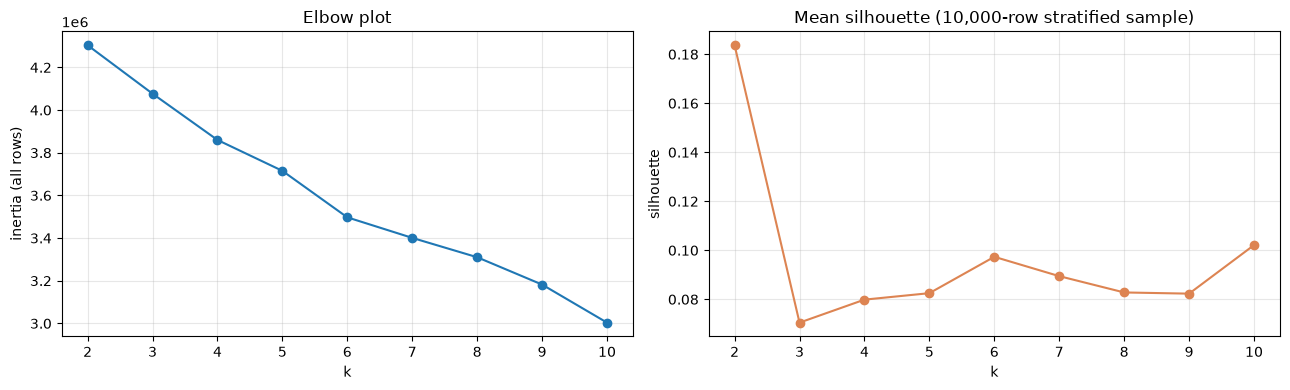

,2,3,4,5,6,7,8,9,10
inertia,4.3041e+06,4.0769e+06,3.8600e+06,3.7152e+06,3.4972e+06,3.4009e+06,3.3102e+06,3.1820e+06,3.0037e+06
drop vs k-1 %,NaN,5.2786e+00,5.3220e+00,3.7514e+00,5.8667e+00,2.7525e+00,2.6685e+00,3.8726e+00,5.6042e+00
silhouette,1.8369e-01,7.0488e-02,7.9867e-02,8.2507e-02,9.7343e-02,8.9455e-02,8.2799e-02,8.2314e-02,1.0212e-01


In [11]:
K_RANGE = range(2, 11)
sil_idx, _ = train_test_split(np.arange(len(data)), train_size=10_000, stratify=y_all,
                              random_state=RANDOM_STATE)
t0 = time.perf_counter()
fits: dict[int, KMeansResult] = {k: kmeans(z_all, k, n_init=3) for k in K_RANGE}
silhouettes = {k: silhouette_score(z_all[sil_idx], fits[k].labels[sil_idx]) for k in K_RANGE}
print(f"K-means for k = 2..10 and silhouettes: {time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(K_RANGE), [fits[k].inertia for k in K_RANGE], marker="o")
axes[0].set(title="Elbow plot", xlabel="k", ylabel="inertia (all rows)")
axes[1].plot(list(K_RANGE), list(silhouettes.values()), marker="o", color="#DD8452")
axes[1].set(title="Mean silhouette (10,000-row stratified sample)", xlabel="k",
            ylabel="silhouette")
plt.tight_layout()
plt.show()
pd.DataFrame({"inertia": {k: fits[k].inertia for k in K_RANGE},
              "drop vs k-1 %": {k: (1 - fits[k].inertia / fits[k - 1].inertia) * 100 if k > 2 else np.nan
                                for k in K_RANGE},
              "silhouette": silhouettes}).T

**Choosing k.** The elbow plot has **no clear elbow**: going from k − 1 to k removes a fairly steady
3–6 % of the inertia all the way to k = 10. The silhouette is highest at **k = 2 (0.18)** by a wide
margin; every k from 3 to 10 scores only 0.07–0.10. So we choose **k = 2**. Even 0.18 is low (values
below about 0.25 are usually read as "no substantial cluster structure"): the respondents form a
continuum, and any clustering of this data is a convenient partition rather than a discovery of
natural groups.

In [12]:
def relabel_by_pc1(result: KMeansResult) -> KMeansResult:
    """Renumber clusters by the PC1 score of their centre (0 = lowest PC1, i.e. best health).

    Cluster numbers are arbitrary; a fixed order makes the tables reproducible and readable.
    The diabetes label is not used.

    Args:
        result: A K-means fit on the standardised features.

    Returns:
        The same clustering with clusters renumbered.
    """
    order = np.argsort(pca_project(result.centres, components, pca_mean, 1)[:, 0])
    new_id = np.empty_like(order)
    new_id[order] = np.arange(len(order))
    return KMeansResult(new_id[result.labels], result.centres[order], result.inertia,
                        result.n_iter)


def cluster_profile(labels: IntArray) -> pd.DataFrame:
    """Size and diabetes prevalence of each cluster.

    Args:
        labels: Cluster index of every row of ``data``.

    Returns:
        One row per cluster: size, share of respondents, diabetic count and prevalence (%).
    """
    grouped = data.assign(cluster=labels).groupby("cluster")
    return pd.DataFrame({
        "size": grouped.size(),
        "share %": grouped.size() / len(data) * 100,
        "diabetic (count)": grouped[LABEL].sum().astype(int),
        "diabetes prevalence %": grouped[LABEL].mean() * 100,
    })


K_CHOSEN = 2  # highest silhouette by a wide margin; the elbow plot has no clear kink
best = relabel_by_pc1(fits[K_CHOSEN])
cluster_table = cluster_profile(best.labels)
print(f"Overall prevalence {y_all.mean() * 100:.1f} % ({y_all.sum():,} diabetic)")
cluster_table

Overall prevalence 15.3 % (35,097 diabetic)


,size,share %,diabetic (count),diabetes prevalence %
cluster,,,,
0,169431,73.8345,16138,9.5248
1,60043,26.1655,18959,31.5757


In [13]:
# Mean of every feature per cluster, in the original units (binary means = share answering yes),
# sorted by how far apart the standardised cluster centres are on that feature.
means = data.assign(cluster=best.labels).groupby("cluster")[FEATURES].mean().T
means.columns = [f"cluster {j}" for j in means.columns]
means["all"] = data[FEATURES].mean()
gap = pd.Series(np.ptp(best.centres, axis=0), index=FEATURES).sort_values(ascending=False)
means.loc[gap.index].assign(**{"centre gap (std units)": gap})

,cluster 0,cluster 1,all,centre gap (std units)
DiffWalk,0.0296,0.6264,0.1858,1.5346
GenHlth,2.2170,3.6878,2.6018,1.3811
PhysHlth,1.5449,13.5314,4.6812,1.3243
Income,6.4591,4.2787,5.8886,1.0418
HeartDiseaseorAttack,0.0419,0.2766,0.1033,0.7710
PhysActivity,0.8206,0.4861,0.7330,0.7561
HighBP,0.3572,0.7284,0.4543,0.7455
MentHlth,2.0054,7.7552,3.5099,0.7450
Education,5.1721,4.4369,4.9797,0.7404
Stroke,0.0128,0.1352,0.0448,0.5917


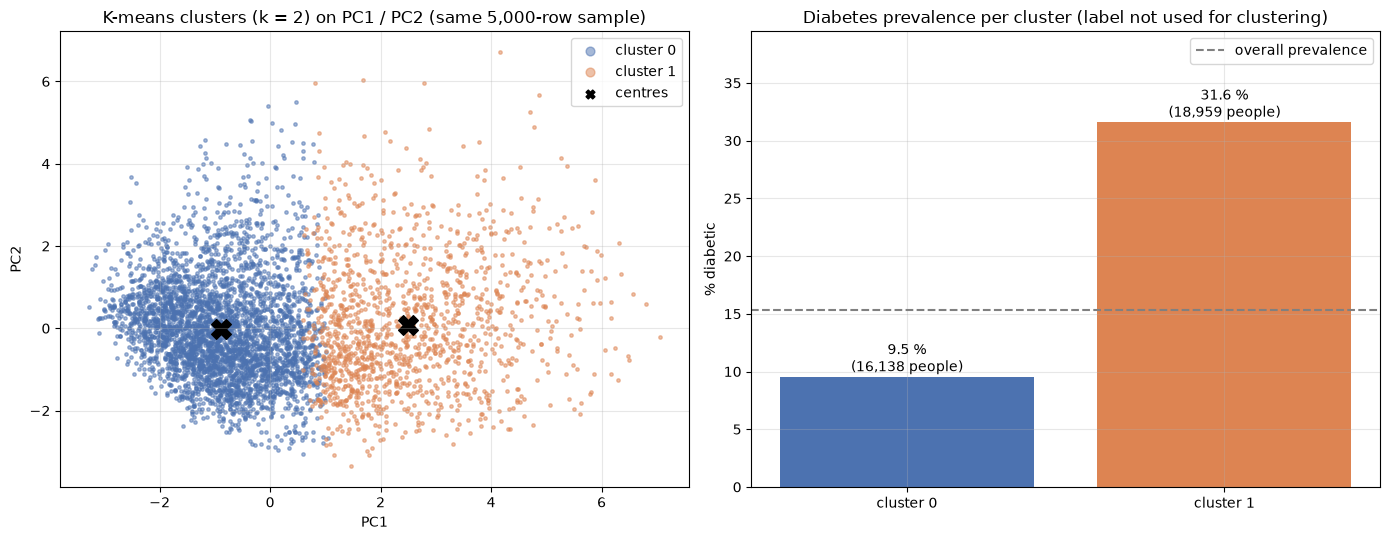

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3",
           "#8C8C8C", "#CCB974", "#64B5CD"]
for j in range(K_CHOSEN):
    pts = sample_idx[best.labels[sample_idx] == j]
    axes[0].scatter(scores_all[pts, 0], scores_all[pts, 1], s=6, alpha=0.5, color=palette[j],
                    label=f"cluster {j}")
centres_pc = pca_project(best.centres, components, pca_mean, 2)
axes[0].scatter(centres_pc[:, 0], centres_pc[:, 1], marker="X", s=200, color="black",
                label="centres")
axes[0].set(title=f"K-means clusters (k = {K_CHOSEN}) on PC1 / PC2 (same 5,000-row sample)",
            xlabel="PC1", ylabel="PC2")
legend = axes[0].legend()
for handle in legend.legend_handles:  # same marker size for points and centres in the legend
    handle.set_sizes([40])

axes[1].bar([f"cluster {j}" for j in range(K_CHOSEN)], cluster_table["diabetes prevalence %"],
            color=palette[:K_CHOSEN])
axes[1].axhline(y_all.mean() * 100, color="grey", linestyle="--", label="overall prevalence")
for j, (p, n) in enumerate(zip(cluster_table["diabetes prevalence %"],
                               cluster_table["diabetic (count)"])):
    axes[1].text(j, p + 0.5, f"{p:.1f} %\n({n:,} people)", ha="center")
axes[1].set(title="Diabetes prevalence per cluster (label not used for clustering)",
            ylabel="% diabetic", ylim=(0, cluster_table["diabetes prevalence %"].max() * 1.25))
axes[1].legend()
plt.tight_layout()
plt.show()

**Observation.** The two clusters split the population along the PC1 "health burden" direction:
* **Cluster 0** (169,431 people, 74 %): fewer health problems. Diabetes prevalence **9.5 %**
  (16,138 people).
* **Cluster 1** (60,043 people, 26 %): poor self-rated health (mean GenHlth 3.7 against 2.2), many
  days of poor physical health (13.5 against 1.5), 63 % with difficulty walking, more heart disease,
  stroke and high blood pressure, older and lower income. Diabetes prevalence **31.6 %**
  (18,959 people).

The label was not used, yet prevalence differs more than threefold between the clusters. That is the
same signal the classifier in notebook 01 uses (GenHlth, HighBP, BMI, DiffWalk and Age are its
strongest features). Note that cluster 1 still has 41k people **without** diabetes, and cluster 0
contains 46 % of all diabetic respondents: a cluster is **not** a diagnosis or a risk tier.

**A finer split for description: k = 4.** The silhouette does not support more than two clusters, but
looking at $k = 4$ shows what K-means does with binary features. Each row lists the features whose
cluster mean is furthest from the overall mean (in standard-deviation units).

In [15]:
best4 = relabel_by_pc1(fits[4])
table4 = cluster_profile(best4.labels)
centre_df = pd.DataFrame(best4.centres, columns=FEATURES)
table4["most distinctive features (centre, std units)"] = [
    ", ".join(f"{f} {centre_df.loc[j, f]:+.1f}"
              for f in centre_df.loc[j].abs().sort_values(ascending=False).index[:4])
    for j in range(4)
]
table4

,size,share %,diabetic (count),diabetes prevalence %,"most distinctive features (centre, std units)"
cluster,,,,,
0,97229,42.3704,4007,4.1212,"HighBP -0.8, Age -0.5, GenHlth -0.5, HighChol ..."
1,81023,35.3081,16900,20.8583,"HighBP +0.7, Age +0.5, HighChol +0.4, PhysHlth..."
2,12183,5.3091,1329,10.9086,"AnyHealthcare -4.2, NoDocbcCost +0.9, Age -0.6..."
3,39039,17.0124,12861,32.9440,"DiffWalk +1.5, PhysHlth +1.5, GenHlth +1.2, In..."


**Observation (k = 4).** The finer split shows two groups along the health-burden direction (a
healthier, younger group at about 4 % prevalence and a group with many limitations at about 33 %), an
older group with high blood pressure and cholesterol (about 21 %), and a small group of about 12,000
people (5 %) that is defined almost entirely by **AnyHealthcare = 0** (no health-care coverage; its
standardised centre is about −4 on that feature).

That last cluster is an artefact of the method, not a population "type": standardising a rare binary
answer gives the few people who answer the rare way a very large coordinate, and Euclidean K-means
then spends a whole cluster on them. This is why the honest notes below matter.

**Honest notes on K-means here**
* **Binary data and Euclidean distance.** 14 of the 21 features are 0/1 and 4 are short ordinal scales.
  K-means assumes continuous features where a squared Euclidean distance is meaningful and a centre (a
  mean) is a sensible representative. *k-prototypes* (Euclidean for numeric features, matching
  dissimilarity for categorical ones) or K-modes would suit this data better; they are not used here.
* **What drives the clusters.** At k = 2 the centres differ most in difficulty walking, general
  health, physical-health days and income (1.0–1.5 standard deviations apart), then heart disease,
  physical activity, blood pressure and mental-health days (about 0.75). Age (0.55) and BMI (0.47)
  matter less than one might expect. It is the same broad "health burden" axis as PC1, driven by
  self-rated health and physical limitation more than by BMI or age.
* **Not clinical subtypes.** These clusters are groups of similar **survey answers**. They are not
  types of diabetes, not risk tiers and not used by the app.

# Part B — Hidden Markov Model and the sum-product algorithm (method demonstration)

> **Synthetic data, method demonstration only.** The sequences below come from the app's demo
> generator (`scripts/seed_demo.py`), which draws each patient's daily readings from a straight-line
> course plus Gaussian noise. They are **not** real patients. Nothing in this part is used by the app:
> it does not raise alerts, does not change limits and detects nothing in real people.

## B0. Data: one observation symbol per day

`scripts/export_hmm_sequences.py` takes the 20 demo patients, generates their 30 days of readings with
a fixed clock and seed, computes each patient's limits with the real threshold engine (one batch run,
as `tests/test_seed_demo.py` does), and classifies every **fasting** reading into a band state.
Because the limits are computed once, at the end of the 30 days, every day is judged against those
final limits; for rohan and meera the trend revision has already tightened the fasting limit (to
122.2 and 126.7 mg/dL), and that tightened limit is applied to their early days too. We use
one observation per day (the fasting reading) and map the five band states to three symbols:

| Symbol | Meaning | Band states |
|---|---|---|
| 0 | in range | `normal` |
| 1 | near a limit | `pre_breach_high`, `pre_breach_low` (within 5 % of a limit) |
| 2 | past a limit | `breach_high`, `breach_low` |

In [16]:
sequences_df = pd.read_csv(SYNTHETIC_DIR / SEQUENCE_FILE)
SYMBOL = {"normal": 0, "pre_breach_high": 1, "pre_breach_low": 1, "breach_high": 2,
          "breach_low": 2}
SYMBOL_NAMES = ["in range", "near a limit", "past a limit"]
N_SYMBOLS = len(SYMBOL_NAMES)
sequences_df["symbol"] = sequences_df["band_state"].map(SYMBOL)
assert sequences_df["symbol"].notna().all(), "unknown band state"
assert (sequences_df["context"] == "fasting").all()

PATIENTS = list(dict.fromkeys(sequences_df["patient_key"]))  # file order
sequences: dict[str, IntArray] = {
    key: grp.sort_values("day")["symbol"].to_numpy().astype(int)
    for key, grp in sequences_df.groupby("patient_key", sort=False)
}
assert all(len(s) == 30 for s in sequences.values())

overview = sequences_df.groupby("patient_key", sort=False).agg(
    status=("diabetes_status", "first"), scenario=("scenario", "first"),
    high_limit=("high_limit_mg_dl", "first"), low_limit=("low_limit_mg_dl", "first"))
for s, name in enumerate(SYMBOL_NAMES):
    overview[name] = [int((sequences[k] == s).sum()) for k in overview.index]
print(f"{len(PATIENTS)} patients x 30 days = {len(sequences_df)} observations")
overview

20 patients x 30 days = 600 observations


,status,scenario,high_limit,low_limit,in range,near a limit,past a limit
patient_key,,,,,,,
meera,diabetes,fasting drifts up into the pre-breach band (~1...,126.7,70.0,24,6,0
rohan,diabetes,significant rising trend; trend revision tight...,122.2,70.0,3,3,24
priya,diabetes,two fasting readings below 54 mg/dL (Level 2 h...,130.0,70.0,28,0,2
kavya,diabetes,fasting slides toward the low limit (pre-breac...,130.0,71.1,7,21,2
imran,diabetes,"post-meal above 180 (breach high), fasting nea...",130.0,70.0,10,16,4
nandini,diabetes,post-meal steady in the pre-breach band (171-180),130.0,70.0,30,0,0
aarav,diabetes,well controlled,130.0,70.0,30,0,0
rahul,diabetes,well controlled,130.0,70.0,30,0,0
lakshmi,diabetes,healthy older adult (no proxy conditions): sta...,130.0,70.0,30,0,0


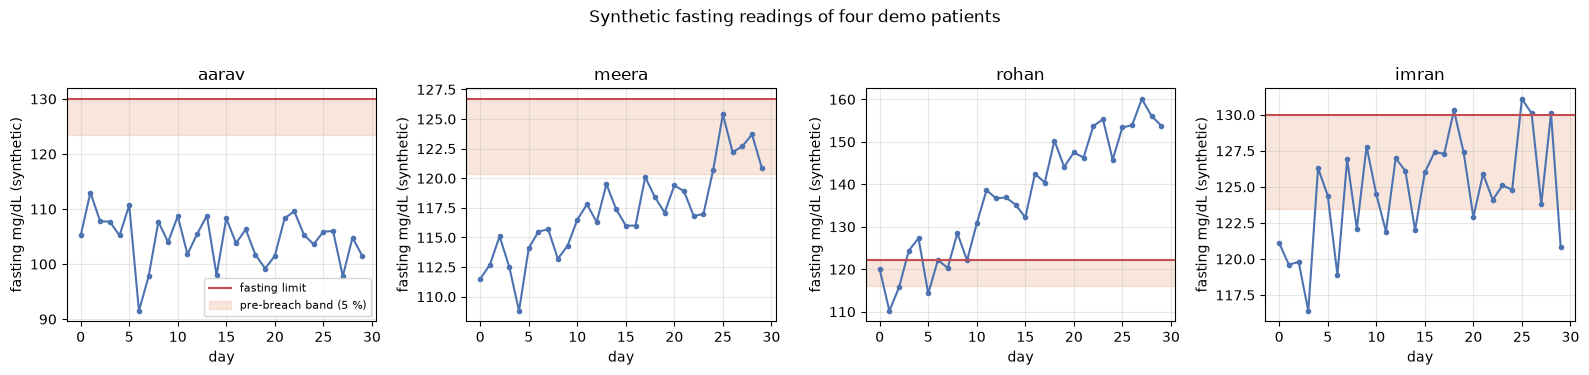

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=False)
for ax, key in zip(axes, ["aarav", "meera", "rohan", "imran"]):
    grp = sequences_df[sequences_df["patient_key"] == key]
    ax.plot(grp["day"], grp["value_mg_dl"], marker="o", ms=3, color="#4C72B0")
    high = grp["high_limit_mg_dl"].iloc[0]
    ax.axhline(high, color="#C44E52", label="fasting limit")
    ax.axhspan(high * 0.95, high, color="#DD8452", alpha=0.2, label="pre-breach band (5 %)")
    ax.set(title=key, xlabel="day", ylabel="fasting mg/dL (synthetic)")
axes[0].legend(fontsize=8)
plt.suptitle("Synthetic fasting readings of four demo patients", y=1.03)
plt.tight_layout()
plt.show()

## B1. A Hidden Markov Model from scratch

An HMM with $K$ hidden states and $M$ observation symbols has three parameters:

* initial distribution $\pi_i = P(z_1 = i)$,
* transition matrix $A_{ij} = P(z_{t+1} = j \mid z_t = i)$,
* emission matrix $B_{ik} = P(o_t = k \mid z_t = i)$.

We use $K = 3$ hidden states. They have no names before fitting; after fitting we name them by what
they emit (**stable** / **drifting** / **out of range**).

**Algorithms** (all from scratch in numpy):

* **Forward:** $\alpha_t(j) = P(o_{1..t}, z_t=j) = \big[\sum_i \alpha_{t-1}(i) A_{ij}\big] B_{j,o_t}$;
  the likelihood is $P(o) = \sum_j \alpha_T(j)$.
* **Backward:** $\beta_t(i) = P(o_{t+1..T} \mid z_t=i) = \sum_j A_{ij} B_{j,o_{t+1}} \beta_{t+1}(j)$.
* **Posterior marginals (forward-backward):** $\gamma_t(i) = P(z_t=i \mid o) \propto \alpha_t(i)\beta_t(i)$.
* **Viterbi:** the single most likely path $\arg\max_z P(z \mid o)$, by dynamic programming with max
  instead of sum (in log space).
* **Baum-Welch (EM):** E-step = expected state and transition counts from forward-backward; M-step =
  normalised counts. Each iteration can never decrease the likelihood.

**Underflow.** A product of 30 probabilities is tiny; for longer sequences it underflows to 0. We use
the **scaled** forward-backward of Rabiner (1989): $\alpha_t$ is normalised to sum to 1 at every step,
and the log-likelihood is $\sum_t \log c_t$ where $c_t$ are the normalisers. Viterbi works with logs.

In [18]:
class HMM(NamedTuple):
    """Discrete hidden Markov model parameters."""

    start: FloatArray  # pi, shape (K,)
    trans: FloatArray  # A, shape (K, K); rows sum to 1
    emit: FloatArray  # B, shape (K, M); rows sum to 1


def forward(hmm: HMM, obs: IntArray) -> tuple[FloatArray, FloatArray]:
    """Scaled forward pass.

    Args:
        hmm: Model parameters.
        obs: Observation symbols, shape (T,).

    Returns:
        ``alpha_hat`` of shape (T, K) with ``alpha_hat[t] = P(z_t | o_1..t)`` (each row sums to
        1), and the scaling factors ``c`` of shape (T,) with ``c[t] = P(o_t | o_1..t-1)``, so that
        ``log P(o) = sum(log c)``.
    """
    alpha = np.zeros((len(obs), len(hmm.start)))
    c = np.zeros(len(obs))
    a = hmm.start * hmm.emit[:, obs[0]]
    for t in range(len(obs)):
        if t > 0:
            a = (alpha[t - 1] @ hmm.trans) * hmm.emit[:, obs[t]]
        c[t] = a.sum()
        alpha[t] = a / c[t]
    return alpha, c


def backward(hmm: HMM, obs: IntArray, c: FloatArray) -> FloatArray:
    """Scaled backward pass, using the forward pass's scaling factors.

    Args:
        hmm: Model parameters.
        obs: Observation symbols, shape (T,).
        c: Scaling factors from :func:`forward`.

    Returns:
        ``beta_hat`` of shape (T, K): ``beta_t(i) / prod(c[t+1:])``, so that
        ``alpha_hat * beta_hat`` is the posterior ``P(z_t = i | o)``.
    """
    beta = np.ones((len(obs), len(hmm.start)))
    for t in range(len(obs) - 2, -1, -1):
        beta[t] = hmm.trans @ (hmm.emit[:, obs[t + 1]] * beta[t + 1]) / c[t + 1]
    return beta


def log_likelihood(hmm: HMM, obs: IntArray) -> float:
    """Log-likelihood ``log P(o)`` of one sequence (forward algorithm).

    Args:
        hmm: Model parameters.
        obs: Observation symbols.

    Returns:
        The natural-log likelihood.
    """
    return float(np.log(forward(hmm, obs)[1]).sum())


def posteriors(hmm: HMM, obs: IntArray) -> tuple[FloatArray, FloatArray, float]:
    """Forward-backward: state posteriors and expected transition counts.

    Args:
        hmm: Model parameters.
        obs: Observation symbols, shape (T,).

    Returns:
        ``gamma`` of shape (T, K) with ``P(z_t = i | o)``, the expected transition counts
        ``sum_t P(z_t = i, z_t+1 = j | o)`` of shape (K, K), and ``log P(o)``.
    """
    alpha, c = forward(hmm, obs)
    beta = backward(hmm, obs, c)
    gamma = alpha * beta
    xi_sum = np.zeros_like(hmm.trans)
    for t in range(len(obs) - 1):
        xi_sum += (alpha[t][:, None] * hmm.trans * (hmm.emit[:, obs[t + 1]] * beta[t + 1])[None, :]
                   / c[t + 1])
    return gamma, xi_sum, float(np.log(c).sum())


def viterbi(hmm: HMM, obs: IntArray) -> tuple[IntArray, float]:
    """Most likely hidden-state path, computed in log space.

    Args:
        hmm: Model parameters.
        obs: Observation symbols, shape (T,).

    Returns:
        The path (shape (T,)) and its joint log-probability ``log P(z, o)``.
    """
    with np.errstate(divide="ignore"):  # log(0) = -inf is the right value for impossible moves
        log_a, log_b, log_pi = np.log(hmm.trans), np.log(hmm.emit), np.log(hmm.start)
    delta = log_pi + log_b[:, obs[0]]
    back = np.zeros((len(obs), len(hmm.start)), dtype=int)
    for t in range(1, len(obs)):
        cand = delta[:, None] + log_a  # cand[i, j]: best path ending in i, then i -> j
        back[t] = cand.argmax(axis=0)
        delta = cand.max(axis=0) + log_b[:, obs[t]]
    path = np.zeros(len(obs), dtype=int)
    path[-1] = int(delta.argmax())
    for t in range(len(obs) - 1, 0, -1):
        path[t - 1] = back[t, path[t]]
    return path, float(delta.max())


def random_hmm(rng: np.random.Generator, n_states: int, n_symbols: int) -> HMM:
    """Random starting parameters: every row drawn from a flat Dirichlet distribution.

    Args:
        rng: Random generator.
        n_states: Number of hidden states K.
        n_symbols: Number of observation symbols M.

    Returns:
        A valid HMM (all rows sum to 1).
    """
    return HMM(rng.dirichlet(np.ones(n_states)), rng.dirichlet(np.ones(n_states), n_states),
               rng.dirichlet(np.ones(n_symbols), n_states))


def baum_welch(seqs: list[IntArray], init: HMM, max_iter: int = 500,
               tol: float = 1e-8) -> tuple[HMM, list[float]]:
    """Fit an HMM to several sequences by expectation-maximisation (Baum-Welch).

    Args:
        seqs: Observation sequences (one per patient).
        init: Starting parameters.
        max_iter: Maximum number of EM iterations.
        tol: Stop when the total log-likelihood improves by less than this.

    Returns:
        The fitted model and the total log-likelihood *before* each M-step (the last entry is
        the likelihood of the returned model).
    """
    hmm, history = init, []
    for _ in range(max_iter):
        start_acc = np.zeros_like(hmm.start)
        trans_acc = np.zeros_like(hmm.trans)
        emit_acc = np.zeros_like(hmm.emit)
        total = 0.0
        for obs in seqs:  # E-step: expected counts, summed over all sequences
            gamma, xi_sum, ll = posteriors(hmm, obs)
            start_acc += gamma[0]
            trans_acc += xi_sum
            for k in range(emit_acc.shape[1]):
                emit_acc[:, k] += gamma[obs == k].sum(axis=0)
            total += ll
        history.append(total)
        if len(history) > 1 and history[-1] - history[-2] < tol:
            break
        # M-step: normalised expected counts. A state nobody visits keeps its old rows.
        trans_rows, emit_rows = trans_acc.sum(1, keepdims=True), emit_acc.sum(1, keepdims=True)
        hmm = HMM(start_acc / start_acc.sum(),
                  np.where(trans_rows > 0, trans_acc / np.maximum(trans_rows, 1e-300), hmm.trans),
                  np.where(emit_rows > 0, emit_acc / np.maximum(emit_rows, 1e-300), hmm.emit))
    return hmm, history

### Verify against brute force

On a short sequence ($T = 8$, so $3^8 = 6{,}561$ state paths) we can enumerate every path $z$,
compute $P(z, o) = \pi_{z_1} B_{z_1 o_1} \prod_t A_{z_{t-1} z_t} B_{z_t o_t}$ directly, and sum. The
forward likelihood, the posteriors and the Viterbi path must agree with the enumeration. We test a
random (unfitted) model so the check does not depend on training.

In [19]:
def brute_force(hmm: HMM, obs: IntArray) -> tuple[float, FloatArray, IntArray]:
    """Exact likelihood, posteriors and best path by enumerating every state path.

    Args:
        hmm: Model parameters.
        obs: A short observation sequence (K**T paths are enumerated).

    Returns:
        ``P(o)``, the posteriors ``P(z_t = i | o)`` of shape (T, K), and the best path.
    """
    n_states = len(hmm.start)
    marg = np.zeros((len(obs), n_states))
    total, best_p, best_path = 0.0, -1.0, None
    for path in itertools.product(range(n_states), repeat=len(obs)):
        p = hmm.start[path[0]] * hmm.emit[path[0], obs[0]]
        for t in range(1, len(obs)):
            p *= hmm.trans[path[t - 1], path[t]] * hmm.emit[path[t], obs[t]]
        total += p
        marg[np.arange(len(obs)), path] += p
        if p > best_p:
            best_p, best_path = p, path
    return total, marg / total, np.array(best_path)


short_obs = sequences["meera"][20:28]  # in range, then drifting near the limit
test_hmm = random_hmm(np.random.default_rng(RANDOM_STATE), 3, N_SYMBOLS)
bf_lik, bf_marg, bf_path = brute_force(test_hmm, short_obs)
gamma_short, _, ll_short = posteriors(test_hmm, short_obs)

assert np.isclose(np.exp(ll_short), bf_lik, rtol=1e-12)
assert np.allclose(gamma_short, bf_marg, atol=1e-12)
assert np.array_equal(viterbi(test_hmm, short_obs)[0], bf_path)
print("short sequence:", short_obs)
print(f"P(o): forward {np.exp(ll_short):.6e}   brute force {bf_lik:.6e}")
print("posteriors, forward-backward == brute force; Viterbi path == best enumerated path", bf_path)

short sequence: [0 0 0 0 1 1 1 1]
P(o): forward 1.026668e-05   brute force 1.026668e-05
posteriors, forward-backward == brute force; Viterbi path == best enumerated path [0 2 0 2 0 2 0 2]


### Fit with Baum-Welch: 20 random restarts

EM only finds a *local* maximum, so we start from 20 random models and keep the one with the highest
log-likelihood. We assert that the log-likelihood never decreases in any run (a classic check that the
E- and M-steps are implemented correctly).

20 restarts in 19.8 s


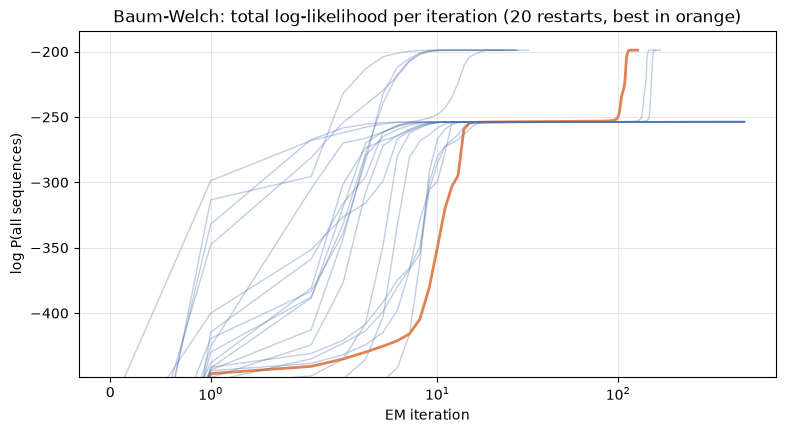

final log-likelihood per restart (sorted): [-198.9  -198.9  -198.9  -198.9  -198.9  -198.9  -198.9  -198.9  -253.41
 -253.42 -253.49 -253.59 -253.62 -253.62 -253.66 -253.66 -253.67 -253.67
 -253.7  -253.7 ]


In [20]:
N_STATES, N_RESTARTS = 3, 20
train_seqs = [sequences[k] for k in PATIENTS]
restart_rng = np.random.default_rng(RANDOM_STATE)
t0 = time.perf_counter()
restarts = [baum_welch(train_seqs, random_hmm(restart_rng, N_STATES, N_SYMBOLS))
            for _ in range(N_RESTARTS)]
print(f"{N_RESTARTS} restarts in {time.perf_counter() - t0:.1f} s")

for _, hist in restarts:  # EM guarantee: non-decreasing (allow float rounding)
    assert np.all(np.diff(hist) >= -1e-9 * np.abs(hist[:-1])), "log-likelihood decreased"
final_ll = np.array([hist[-1] for _, hist in restarts])
best_restart = int(final_ll.argmax())
fitted_raw, best_history = restarts[best_restart]

fig, ax = plt.subplots(figsize=(9, 4.5))
for r, (_, hist) in enumerate(restarts):
    ax.plot(hist, color="#DD8452" if r == best_restart else "#4C72B0",
            alpha=1.0 if r == best_restart else 0.35, lw=2 if r == best_restart else 1)
ax.set(title="Baum-Welch: total log-likelihood per iteration (20 restarts, best in orange)",
       xlabel="EM iteration", ylabel="log P(all sequences)", xscale="symlog")
ax.set_ylim(final_ll.max() - 250, final_ll.max() + 15)
plt.show()
print("final log-likelihood per restart (sorted):", np.round(np.sort(final_ll)[::-1], 2))

### Naming the states (label switching)

Hidden-state numbers are arbitrary: permuting states 0/1/2 (with the matching rows and columns of
$\pi$, $A$, $B$) gives exactly the same likelihood, so different restarts return the "same" model
under different numberings. We fix this explicitly: sort the states by their **expected symbol**
$\sum_k k\,B_{ik}$ and name them, in that order, **stable**, **drifting**, **out of range**. Then all
the good restarts can be compared directly.

In [21]:
STATE_NAMES = ["stable", "drifting", "out of range"]


def align_states(hmm: HMM) -> tuple[HMM, IntArray]:
    """Reorder hidden states by expected emitted symbol (0 = in range ... 2 = past a limit).

    Args:
        hmm: Fitted model with arbitrary state numbering.

    Returns:
        The same model with states renumbered (stable, drifting, out of range), and the
        permutation ``perm`` such that new state ``i`` is old state ``perm[i]``.
    """
    perm = np.argsort(hmm.emit @ np.arange(hmm.emit.shape[1]))
    return HMM(hmm.start[perm], hmm.trans[np.ix_(perm, perm)], hmm.emit[perm]), perm


fitted, perm = align_states(fitted_raw)
print("raw state numbering of the best restart -> named:",
      {int(old): STATE_NAMES[new] for new, old in enumerate(perm)})

# Label switching made visible: every restart within 0.01 of the best log-likelihood, once
# aligned, should give the same matrices.
near_best = [align_states(h)[0] for h, hist in restarts if hist[-1] > final_ll.max() - 0.01]
spread = max(np.abs(np.concatenate([m.trans - fitted.trans, m.emit - fitted.emit])).max()
             for m in near_best)
raw_perms = {tuple(align_states(h)[1]) for h, hist in restarts if hist[-1] > final_ll.max() - 0.01}
print(f"{len(near_best)} restarts reach the best likelihood with {len(raw_perms)} different raw "
      f"numberings; after alignment their A and B differ by at most {spread:.1e}")

names = pd.Index(STATE_NAMES, name="state")
display(pd.Series(fitted.start, index=names, name="initial pi").to_frame().T)
display(pd.DataFrame(fitted.trans, index=names, columns=[f"-> {s}" for s in STATE_NAMES]))
pd.DataFrame(fitted.emit, index=names, columns=[f"emits {s}" for s in SYMBOL_NAMES])

raw state numbering of the best restart -> named: {2: 'stable', 0: 'drifting', 1: 'out of range'}
8 restarts reach the best likelihood with 4 different raw numberings; after alignment their A and B differ by at most 8.3e-09


state,stable,drifting,out of range
initial pi,0.7438,0.2562,2.4514e-39


,-> stable,-> drifting,-> out of range
state,,,
stable,9.9235e-01,7.6546e-03,2.5566e-34
drifting,3.0423e-93,9.7807e-01,2.1931e-02
out of range,9.2687e-83,7.9137e-11,1.0000e+00


,emits in range,emits near a limit,emits past a limit
state,,,
stable,0.9872,0.0052,0.0077
drifting,0.2401,0.7373,0.0227
out of range,0.0491,0.0992,0.8517


**The fitted model (best of 20 restarts).** 8 of the 20 restarts reach the same best log-likelihood
(−198.9) under 4 different raw state numberings; once aligned, their matrices agree to about 1e-8,
so the label switching is handled. The other 12 stop at a worse local optimum (about −253.5), which
is why several restarts are needed.

* **Emissions name the states clearly:** *stable* emits "in range" 98.7 % of the time, *drifting* emits
  "near a limit" 73.7 %, *out of range* emits "past a limit" 85.2 %.
* **Transitions:** *stable* stays stable 99.2 % per day and moves to *drifting* 0.8 %; *drifting* stays
  97.8 % and moves to *out of range* 2.2 %; *out of range* never leaves. No patient ever returns to
  *stable*, because the generator draws every course as a straight line or a constant: no synthetic
  patient recovers. The model has learned the **generator's** one-way drift, not physiology.
* **Initial distribution:** 74 % *stable*, 26 % *drifting* (five patients are near a limit from day 0),
  and essentially 0 *out of range*.

## B2. Results: Viterbi paths for every patient

Patients are grouped by what the generator was told to produce (their `scenario`).

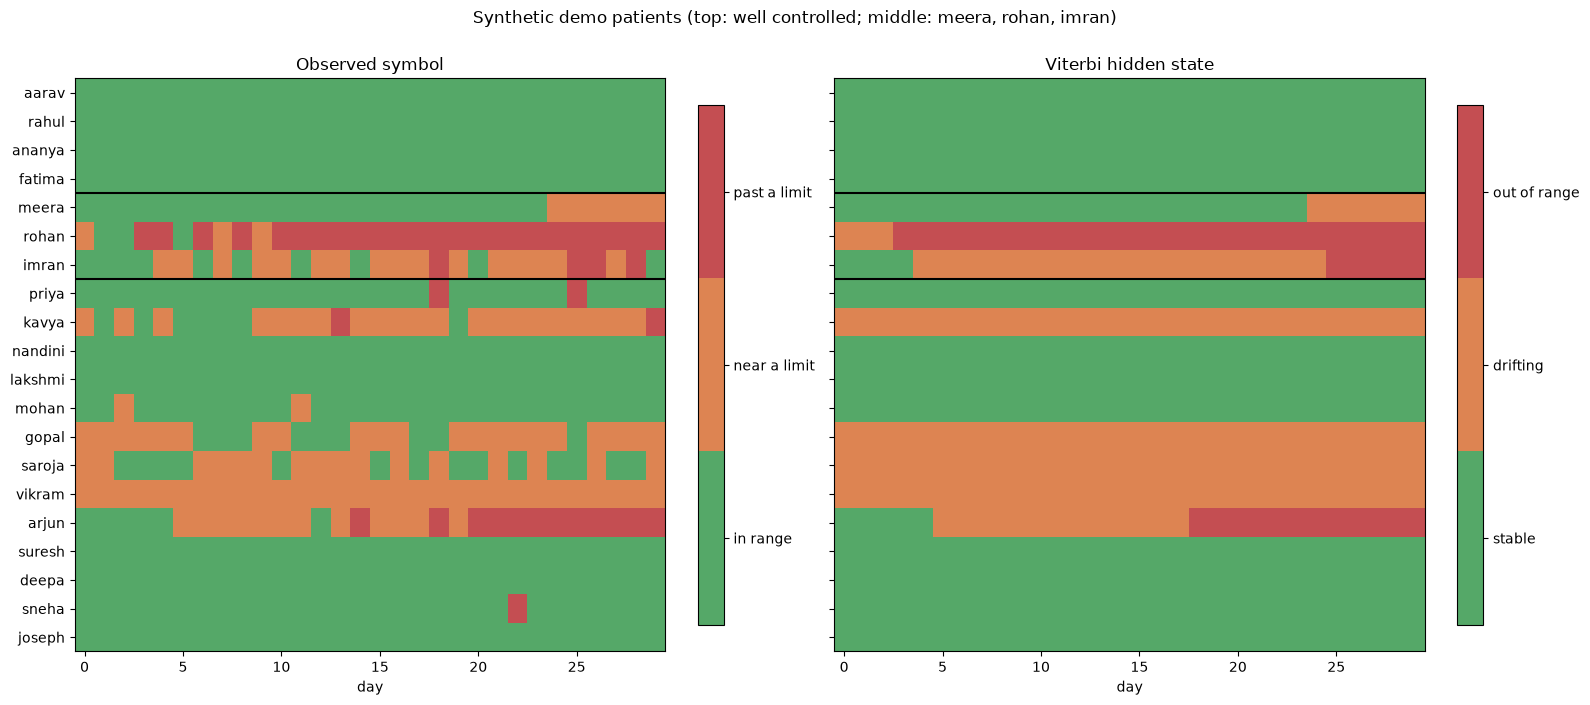

In [22]:
WELL_CONTROLLED = ["aarav", "rahul", "ananya", "fatima"]
NOT_STABLE = ["meera", "rohan", "imran"]
order = WELL_CONTROLLED + NOT_STABLE + [k for k in PATIENTS if k not in WELL_CONTROLLED + NOT_STABLE]
paths = {k: viterbi(fitted, sequences[k])[0] for k in PATIENTS}

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
state_cmap = ListedColormap(["#55A868", "#DD8452", "#C44E52"])
for ax, matrix, title, labels in [
    (axes[0], np.array([sequences[k] for k in order]), "Observed symbol", SYMBOL_NAMES),
    (axes[1], np.array([paths[k] for k in order]), "Viterbi hidden state", STATE_NAMES),
]:
    im = ax.imshow(matrix, cmap=state_cmap, vmin=-0.5, vmax=2.5, aspect="auto")
    ax.set(title=title, xlabel="day", yticks=range(len(order)), yticklabels=order)
    ax.grid(False)
    for y in (len(WELL_CONTROLLED) - 0.5, len(WELL_CONTROLLED + NOT_STABLE) - 0.5):
        ax.axhline(y, color="black", lw=1.5)
    cbar = fig.colorbar(im, ax=ax, ticks=[0, 1, 2], fraction=0.04)
    cbar.ax.set_yticklabels(labels)
plt.suptitle("Synthetic demo patients (top: well controlled; middle: meera, rohan, imran)", y=1.0)
plt.tight_layout()
plt.show()

In [23]:
rows = []
for key in order:
    path = paths[key]
    stable_share = float((path == 0).mean())
    expected = ("mostly stable" if key in WELL_CONTROLLED
                else "not mostly stable" if key in NOT_STABLE else "-")
    agrees = (stable_share > 0.5 if key in WELL_CONTROLLED
              else stable_share <= 0.5 if key in NOT_STABLE else np.nan)
    first_non_stable = int(np.argmax(path != 0)) if (path != 0).any() else None
    rows.append({"patient": key, "scenario": overview.loc[key, "scenario"],
                 **{f"days {s}": int((path == i).sum()) for i, s in enumerate(STATE_NAMES)},
                 "first non-stable day": first_non_stable, "expected": expected,
                 "agrees": agrees})
agreement = pd.DataFrame(rows).set_index("patient")
checked = agreement.loc[WELL_CONTROLLED + NOT_STABLE]
print(f"Agreement with the expected pattern: {int(checked['agrees'].sum())} of {len(checked)} "
      "named patients")
agreement

Agreement with the expected pattern: 6 of 7 named patients


,scenario,days stable,days drifting,days out of range,first non-stable day,expected,agrees
patient,,,,,,,
aarav,well controlled,30,0,0,NaN,mostly stable,True
rahul,well controlled,30,0,0,NaN,mostly stable,True
ananya,normal readings,30,0,0,NaN,mostly stable,True
fatima,normal readings,30,0,0,NaN,mostly stable,True
meera,fasting drifts up into the pre-breach band (~1...,24,6,0,24.0,not mostly stable,False
rohan,significant rising trend; trend revision tight...,0,3,27,0.0,not mostly stable,True
imran,"post-meal above 180 (breach high), fasting nea...",4,21,5,4.0,not mostly stable,True
priya,two fasting readings below 54 mg/dL (Level 2 h...,30,0,0,NaN,-,NaN
kavya,fasting slides toward the low limit (pre-breac...,0,30,0,0.0,-,NaN


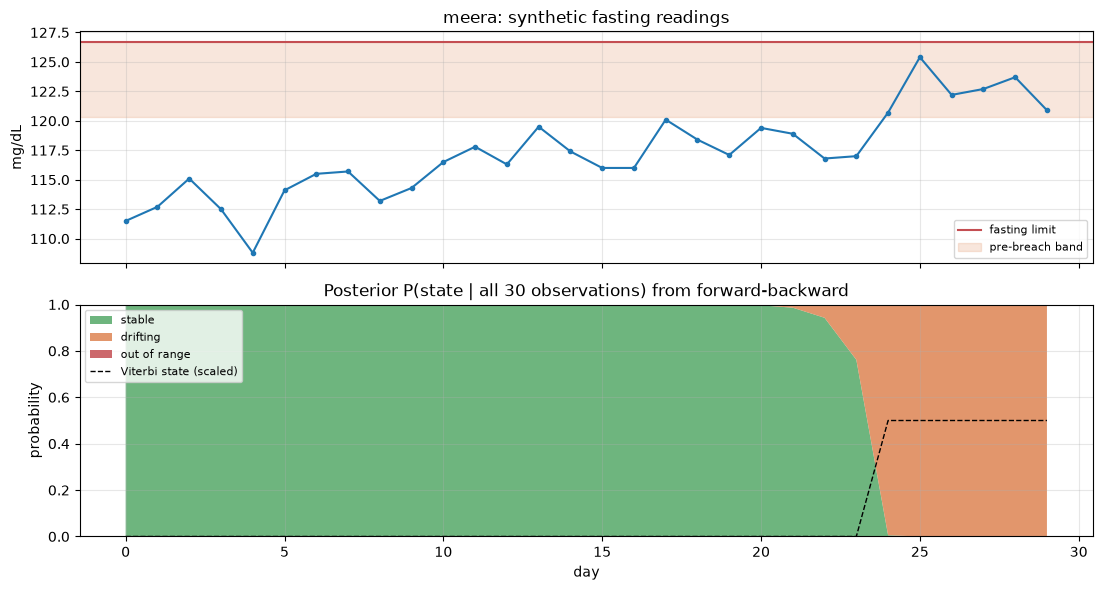

In [24]:
# Posterior state probabilities for one drifting patient: the soft version of the Viterbi path.
key = "meera"
gamma_m, _, _ = posteriors(fitted, sequences[key])
grp = sequences_df[sequences_df["patient_key"] == key]
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(grp["day"], grp["value_mg_dl"], marker="o", ms=3)
axes[0].axhline(grp["high_limit_mg_dl"].iloc[0], color="#C44E52", label="fasting limit")
axes[0].axhspan(grp["high_limit_mg_dl"].iloc[0] * 0.95, grp["high_limit_mg_dl"].iloc[0],
                color="#DD8452", alpha=0.2, label="pre-breach band")
axes[0].set(title=f"{key}: synthetic fasting readings", ylabel="mg/dL")
axes[0].legend(fontsize=8)
axes[1].stackplot(np.arange(30), gamma_m.T, labels=STATE_NAMES,
                  colors=["#55A868", "#DD8452", "#C44E52"], alpha=0.85)
axes[1].plot(np.arange(30), paths[key] / 2, "k--", lw=1, label="Viterbi state (scaled)")
axes[1].set(title="Posterior P(state | all 30 observations) from forward-backward",
            xlabel="day", ylabel="probability", ylim=(0, 1))
axes[1].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Agreement with the generator's scenarios: 6 of 7 named patients.**
* **Well controlled** (aarav, rahul, ananya, fatima): *stable* on all 30 days, as expected.
* **rohan** (rising trend): *out of range* on 27 days, as expected.
* **imran** (fasting near 130, post-meal breaches): *drifting* on 21 days and *out of range* on 5, as
  expected. Note that his post-meal breaches are **not** in this data (fasting readings only); he is
  "not stable" because his fasting values sit near the 130 limit.
* **meera** (drift into the pre-breach band): **fails** the "not mostly stable" test: *stable* on 24
  days. The HMM does mark the change at the right moment (*drifting* from day 24, the first fasting
  reading in the pre-breach band), but her drift is slow and only reaches the band in the last 6 days.

**Where it fails or misleads**
* **Isolated serious readings are smoothed away.** priya's two fasting readings below 54 mg/dL
  (Level 2 hypoglycaemia; days 18 and 25) and sneha's breach-low reading are labelled *stable*: a single
  "past a limit" day costs less likelihood than two state switches. This is the opposite of what a
  safety system needs, and it is why every reading must still go through the threshold engine.
* **"Drifting" means "steadily near a limit", not "changing".** gopal, saroja, vikram and kavya are
  *drifting* on all 30 days because their (synthetic) values sit flat inside a pre-breach band.
* The HMM mostly reproduces the band states it was given, with smoothing. With 20 short synthetic
  sequences and only 3 symbols, it adds little information beyond the band states.

> **Honest note.** The generator is **not** an HMM (it is a straight line plus Gaussian noise, then
> thresholded), the data is small and synthetic, and the "true" states are unknown. This section shows
> that the algorithms work and are verified; it does **not** show that these states exist in real
> patients or measure real glycaemic control.

## B3. The sum-product algorithm on the HMM's factor graph

A **factor graph** is a bipartite graph of *variable nodes* and *factor nodes*; the joint distribution
is the product of the factors. An HMM with the observations fixed is a **chain**:

$$P(z_1,\dots,z_T, o) \;=\; \underbrace{\pi(z_1)}_{\text{prior}}
\prod_{t=1}^{T} \underbrace{B(z_t, o_t)}_{\text{emission } e_t(z_t)}
\prod_{t=2}^{T} \underbrace{A(z_{t-1}, z_t)}_{\text{transition}}$$

* variable nodes: the hidden states $z_1, \dots, z_T$ (the observations are fixed, so they are folded
  into the emission factors);
* factor nodes: one prior factor on $z_1$, one emission factor $e_t$ on each $z_t$, and one transition
  factor between each pair $z_{t-1}, z_t$.

**Sum-product** passes two kinds of messages along the edges:

* variable → factor: $\mu_{z \to f}(z) = \prod_{g \in N(z) \setminus f} \mu_{g \to z}(z)$;
* factor → variable: $\mu_{f \to z}(z) = \sum_{z'} f(z, z')\,\mu_{z' \to f}(z')$ (a unary factor just
  sends its table).

On a tree (and a chain is a tree), the product of all messages arriving at a variable is its exact
marginal, and the sum of that product is the normalising constant $Z = P(o)$. Below is a **generic**
implementation (any tree of unary and pairwise factors, not HMM-specific code), with messages
normalised to sum to 1 and their scales tracked in log space so $\log Z$ is still exact.

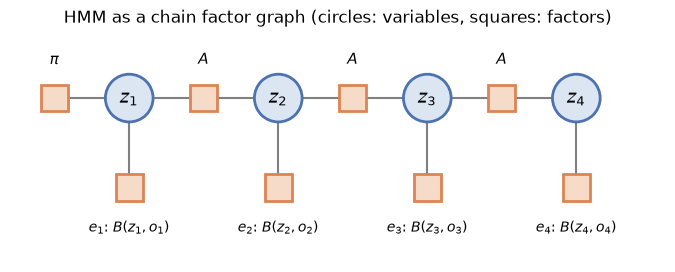

In [25]:
def draw_chain_factor_graph(n_steps: int = 4) -> None:
    """Draw the HMM's chain factor graph for ``n_steps`` time steps.

    Args:
        n_steps: Number of hidden-state variables to draw.
    """
    fig, ax = plt.subplots(figsize=(11, 3))
    for t in range(n_steps):
        x = 2.0 * t
        ax.add_patch(plt.Circle((x, 0), 0.32, fc="#DCE6F2", ec="#4C72B0", lw=2, zorder=3))
        ax.text(x, 0, f"$z_{t + 1}$", ha="center", va="center", fontsize=13, zorder=4)
        ax.add_patch(plt.Rectangle((x - 0.18, -1.38), 0.36, 0.36, fc="#F6DCC8", ec="#DD8452",
                                   lw=2, zorder=3))
        ax.text(x, -1.65, f"$e_{t + 1}$: $B(z_{t + 1}, o_{t + 1})$", ha="center", va="top",
                fontsize=10)
        ax.plot([x, x], [-0.32, -1.02], color="grey", zorder=1)
        if t > 0:
            ax.add_patch(plt.Rectangle((x - 1.18, -0.18), 0.36, 0.36, fc="#F6DCC8", ec="#DD8452",
                                       lw=2, zorder=3))
            ax.text(x - 1.0, 0.45, "$A$", ha="center", fontsize=11)
            ax.plot([x - 2 + 0.32, x - 0.32], [0, 0], color="grey", zorder=1)
    ax.add_patch(plt.Rectangle((-1.18, -0.18), 0.36, 0.36, fc="#F6DCC8", ec="#DD8452", lw=2,
                               zorder=3))
    ax.text(-1.0, 0.45, r"$\pi$", ha="center", fontsize=11)
    ax.plot([-0.82, -0.32], [0, 0], color="grey", zorder=1)
    ax.set(xlim=(-1.6, 2.0 * n_steps - 0.8), ylim=(-2.2, 0.9), aspect="equal",
           title="HMM as a chain factor graph (circles: variables, squares: factors)")
    ax.axis("off")
    plt.show()


draw_chain_factor_graph()

In [26]:
@dataclass(frozen=True)
class Factor:
    """A factor of a factor graph over one or two discrete variables."""

    variables: tuple[int, ...]  # variable indices (1 or 2)
    table: FloatArray  # shape (card,) or (card, card); axis order follows ``variables``


class Message(NamedTuple):
    """A message vector with the log of the scale that was divided out of it."""

    vector: FloatArray
    log_scale: float


def sum_product(n_vars: int, factors: list[Factor],
                mode: Literal["sum", "max"] = "sum",
                normalise: bool = True) -> tuple[list[FloatArray], float]:
    """Belief propagation on a tree-structured factor graph of unary and pairwise factors.

    Every message is computed once (memoised) by recursion from the leaves. With
    ``normalise=True`` each message is rescaled (to sum 1 for sum-product, max 1 for max-product)
    and the scale is carried in log space, so nothing underflows and ``log Z`` stays exact.

    Args:
        n_vars: Number of variables; they are numbered ``0 .. n_vars - 1``.
        factors: The factors; the graph must be a tree (connected, no cycles).
        mode: ``"sum"`` for marginals (sum-product) or ``"max"`` for max-marginals (max-product).
        normalise: Rescale messages (``False`` shows the raw, unnormalised messages).

    Returns:
        The normalised (max-)marginal of every variable, and ``log Z``: the log of the sum (or,
        for ``"max"``, the maximum) over all joint assignments of the product of the factors.

    Raises:
        ValueError: If a factor has more than two variables or the graph is not a tree.
    """
    if any(len(f.variables) not in (1, 2) for f in factors):
        raise ValueError("only unary and pairwise factors are supported")
    n_edges = sum(len(f.variables) for f in factors)
    if n_edges != n_vars + len(factors) - 1:  # a connected graph is a tree iff |E| = |V| - 1
        raise ValueError("factor graph is not a tree")
    reduce = np.sum if mode == "sum" else np.max
    var_nb: list[list[int]] = [[] for _ in range(n_vars)]
    for fi, f in enumerate(factors):
        for v in f.variables:
            var_nb[v].append(fi)
    memo: dict[tuple[str, int, int], Message] = {}

    def rescale(vector: FloatArray, log_scale: float) -> Message:
        if not normalise:
            return Message(vector, log_scale)
        s = float(reduce(vector))
        return Message(vector / s, log_scale + np.log(s))

    def var_to_factor(v: int, fi: int) -> Message:
        key = ("v", v, fi)
        if key not in memo:
            vector, log_scale = np.ones(len(factors[var_nb[v][0]].table)), 0.0
            for g in var_nb[v]:
                if g != fi:
                    m = factor_to_var(g, v)
                    vector, log_scale = vector * m.vector, log_scale + m.log_scale
            memo[key] = rescale(vector, log_scale)
        return memo[key]

    def factor_to_var(fi: int, v: int) -> Message:
        key = ("f", fi, v)
        if key not in memo:
            f = factors[fi]
            if len(f.variables) == 1:
                memo[key] = rescale(f.table.astype(float), 0.0)
            else:
                other = f.variables[1] if f.variables[0] == v else f.variables[0]
                table = f.table if f.variables[0] == v else f.table.T  # axis 0 = v
                incoming = var_to_factor(other, fi)
                memo[key] = rescale(reduce(table * incoming.vector[None, :], axis=1),
                                    incoming.log_scale)
        return memo[key]

    marginals, log_z = [], 0.0
    for v in range(n_vars):
        belief, log_scale = np.ones(len(factors[var_nb[v][0]].table)), 0.0
        for fi in var_nb[v]:
            m = factor_to_var(fi, v)
            belief, log_scale = belief * m.vector, log_scale + m.log_scale
        total = float(reduce(belief))
        marginals.append(belief / total)
        if v == 0:  # Z is the same at every variable on a tree; read it at the first one
            log_z = log_scale + float(np.log(total))
    return marginals, log_z


def hmm_factor_graph(hmm: HMM, obs: IntArray) -> list[Factor]:
    """Build the HMM's chain factor graph for one observation sequence.

    Args:
        hmm: Model parameters.
        obs: Observation symbols, shape (T,).

    Returns:
        Factors: prior on z_0, emission e_t on every z_t, transition A between z_t-1 and z_t.
    """
    factors = [Factor((0,), hmm.start)]
    factors += [Factor((t,), hmm.emit[:, o]) for t, o in enumerate(obs)]
    factors += [Factor((t - 1, t), hmm.trans) for t in range(1, len(obs))]
    return factors

**Checks.** On every patient's 30-day sequence with the fitted model, the sum-product marginals must
equal the forward-backward posteriors and $\log Z$ must equal the forward log-likelihood. On the
short sequence they must also equal brute force, including with **unnormalised** messages
($Z$ read directly as the sum of the belief).

In [27]:
for k in PATIENTS:
    obs_k = sequences[k]
    marg_k, log_z_k = sum_product(len(obs_k), hmm_factor_graph(fitted, obs_k))
    gamma_k, _, ll_k = posteriors(fitted, obs_k)
    assert np.allclose(np.array(marg_k), gamma_k, atol=1e-10), k
    assert np.isclose(log_z_k, ll_k, rtol=1e-12), k
print(f"All {len(PATIENTS)} sequences: sum-product marginals == forward-backward posteriors, "
      "log Z == forward log-likelihood")

graph_short = hmm_factor_graph(test_hmm, short_obs)
marg_norm, log_z_norm = sum_product(len(short_obs), graph_short)
marg_raw, log_z_raw = sum_product(len(short_obs), graph_short, normalise=False)
assert np.allclose(np.array(marg_norm), bf_marg, atol=1e-12)
assert np.allclose(np.array(marg_raw), bf_marg, atol=1e-12)
assert np.isclose(np.exp(log_z_raw), bf_lik, rtol=1e-12)
assert np.isclose(np.exp(log_z_norm), bf_lik, rtol=1e-12)
pd.DataFrame({"P(o)": [bf_lik, np.exp(ll_short), np.exp(log_z_norm), np.exp(log_z_raw)]},
             index=["brute force (6,561 paths)", "forward algorithm",
                    "sum-product, normalised messages", "sum-product, unnormalised messages"])

All 20 sequences: sum-product marginals == forward-backward posteriors, log Z == forward log-likelihood


,P(o)
"brute force (6,561 paths)",1.0267e-05
forward algorithm,1.0267e-05
"sum-product, normalised messages",1.0267e-05
"sum-product, unnormalised messages",1.0267e-05


**Forward-backward *is* sum-product on a chain.** On the chain, the messages that travel left to right
(prior → $z_1$ → transition → $z_2$ → …, each multiplied by the emission factor on the way) are
exactly the forward variables: the message arriving at $z_t$ from the left, times $e_t$, is
$\alpha_t$. The messages that travel right to left are the backward variables $\beta_t$. The belief at
$z_t$ is "left message × emission × right message" $= \alpha_t \beta_t \propto \gamma_t$, and the
normalisers we track are the same scaling factors $c_t$ that keep the forward pass from underflowing.
The generic algorithm reproduces the HMM-specific one because the HMM's factor graph is a tree.

### Max-product = Viterbi (optional)

Replacing every sum by a max gives **max-product**. Each variable's max-marginal
$\max_{z_{-t}} P(z, o)$ is then maximised by the state $z_t$ of the single best path (when that path is
unique), and the maximum itself is the Viterbi path probability.

In [28]:
for k in PATIENTS:
    obs_k = sequences[k]
    max_marg, log_max = sum_product(len(obs_k), hmm_factor_graph(fitted, obs_k), mode="max")
    vit_path, vit_logp = viterbi(fitted, obs_k)
    assert np.array_equal(np.array([m.argmax() for m in max_marg]), vit_path), k
    assert np.isclose(log_max, vit_logp, rtol=1e-12), k
print(f"All {len(PATIENTS)} sequences: argmax of the max-product max-marginals == Viterbi path, "
      "and the max equals the Viterbi log-probability")

All 20 sequences: argmax of the max-product max-marginals == Viterbi path, and the max equals the Viterbi log-probability


# C. Conclusions

| Method | What it showed here | Main limitation | Relation to the advisor |
|---|---|---|---|
| **PCA** (BRFSS) | One moderate common direction (PC1, 15.6 %: overall health burden); 14 of 21 components for 80 % of variance; diabetic respondents lie further along PC1. From-scratch PCA equals scikit-learn. | Mostly binary/ordinal data (MCA/FAMD would be the proper tools). | **Understanding the survey population.** PCA did **not** improve the risk model (fewer components always lowered PR-AUC; all components equals no PCA), so the app keeps the original features. |
| **K-means** (BRFSS) | Weak structure (best silhouette 0.18 at k = 2). The two clusters split along health burden, with diabetes prevalence 9.5 % vs 31.6 %. From-scratch Lloyd + k-means++ equals scikit-learn from the same start. | Euclidean distance on binary features creates artefact clusters (e.g. "no health-care coverage" at k = 4); k-prototypes would suit better. | **Understanding the survey population** only. Clusters are not clinical types or risk tiers, and the app does not use them. |
| **HMM** (synthetic) | Forward, backward, forward-backward, Viterbi and Baum-Welch implemented and checked against brute force; EM never decreased the likelihood; states nameable as stable / drifting / out of range; 6 of 7 named demo patients matched their scenario. | Synthetic, small data from a non-HMM generator; smooths away isolated dangerous readings (Level 2 hypoglycaemia); states learned the generator's one-way drift. | **A possible future way to summarise a patient's control over time** for a practitioner. Before any clinical use it would need real data, validation against clinical outcomes and practitioner oversight. It is **not** used by the app to raise alerts or change limits. |
| **Sum-product** (synthetic) | Generic message passing on the chain factor graph gives exactly the forward-backward posteriors, the brute-force marginals and the likelihood (normalised or not); max-product gives the Viterbi path. | Exact only on trees (chains); loopy graphs need approximations. | Explains *why* forward-backward works; no direct use in the app. |

**Limitations overall**
* BRFSS 2015 is a self-reported US telephone survey; the patterns may not transfer to Indian users.
* Part A is exploratory: no clustering or projection is claimed to be clinically meaningful.
* Part B's data is synthetic. Agreement with the generator's scenarios only shows that the method
  recovers patterns that were put into the data on purpose.
* The advisor's alerts remain rule-based: every reading is checked against the personal limits by the
  threshold engine (R3). Nothing in this notebook changes that.

In [29]:
print(f"Notebook runtime: {time.perf_counter() - NOTEBOOK_START:.0f} s")

Notebook runtime: 62 s
